In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import chart_studio.plotly as ply
import os
from scipy import interpolate as interp
from scipy.signal import spectrogram, firwin, filtfilt, hilbert
from utilities.signal_analysis_utils import get_harmonic_envelope, get_total_envelope
import utm

In [41]:
mag_path = 'data/mag.csv'
gps_path = 'data/gps.csv'

# Magnetic secondary coil data acquisition rate and primary coil driving frequency
sample_rate = int(2e3) # in [Hz]
driving_frequency = 100 # in [Hz]

mag_data = pd.read_csv(mag_path)
mag_times = mag_data['Times (s)'].to_numpy() # in [s]
mag_ch1_voltages = mag_data['Ch 1 (V)'].to_numpy()
mag_ch2_voltages = mag_data['Ch 2 (V)'].to_numpy()
mag_primary_voltages = mag_data['Primary (V)'].to_numpy()
# AC voltages computed by subtracting means from raw voltages
mag_ch1_ac_voltages = mag_ch1_voltages-np.mean(mag_ch1_voltages)
mag_ch2_ac_voltages = mag_ch2_voltages-np.mean(mag_ch2_voltages)
mag_primary_ac_voltages = mag_primary_voltages-np.mean(mag_primary_voltages)

#Trimming Start and End of Run as Determined Later
# mag_times = mag_times[5*sample_rate:-5*sample_rate]
# mag_ch1_ac_voltages = mag_ch1_ac_voltages[5*sample_rate:-5*sample_rate]
# mag_ch2_ac_voltages = mag_ch2_ac_voltages[5*sample_rate:-5*sample_rate]
# mag_primary_ac_voltages = mag_primary_ac_voltages[5*sample_rate:-5*sample_rate]

gps_data = pd.read_csv(gps_path)
gps_times = gps_data['Times (s)'].to_numpy()
gps_lat = gps_data['Latitude'].to_numpy()
gps_lon = gps_data['Longitude'].to_numpy()
gps_headings = gps_data['Heading'].to_numpy()

#Trimming Start and End of Run as Determined Later
gps_times = gps_times
gps_lat = gps_lat
gps_lon = gps_lon
gps_headings = gps_headings

# Conversion from GPS global latitude and longitude to UTM latitude and longitude (in [m])
utm_lat, utm_lon, zone_num, zone_letter = utm.from_latlon(gps_lat, gps_lon)

Computation of RMS Voltages and Harmonic Envelopes

In [105]:
# Computes RMS voltages
num_rms_bins = len(mag_ch1_ac_voltages) // sample_rate
mag_rms_times = mag_times[np.arange(num_rms_bins) * sample_rate]
mag_ch1_rms_voltages = np.array([
    np.sqrt(np.mean(np.square(mag_ch1_ac_voltages[i * sample_rate:(i + 1) * sample_rate])))
    for i in range(num_rms_bins)
])
mag_ch2_rms_voltages = np.array([
    np.sqrt(np.mean(np.square(mag_ch2_ac_voltages[i * sample_rate:(i + 1) * sample_rate])))
    for i in range(num_rms_bins)
])
mag_ch1_rms_voltages -= np.mean(mag_ch1_rms_voltages)
mag_ch2_rms_voltages -= np.mean(mag_ch2_rms_voltages)

# Computes harmonic envelopes
mag_ch1_fundamental_envelope = get_harmonic_envelope(mag_ch1_ac_voltages, sample_rate, mag_primary_ac_voltages, driving_frequency, 1)[2]
mag_ch1_fundamental_envelope = mag_ch1_fundamental_envelope - np.mean(mag_ch1_fundamental_envelope)
mag_ch2_fundamental_envelope = get_harmonic_envelope(mag_ch2_ac_voltages, sample_rate, mag_primary_ac_voltages, driving_frequency, 1)[2]
mag_ch2_fundamental_envelope = mag_ch2_fundamental_envelope - np.mean(mag_ch2_fundamental_envelope)

edge_detection_signals = (
    mag_ch1_rms_voltages.copy(),
    mag_ch2_rms_voltages.copy(),
    mag_ch1_fundamental_envelope.copy(),
    mag_ch2_fundamental_envelope.copy(),
)

In [106]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x= (mag_times[::sample_rate]-mag_data['Times (s)'][0]), 
    y= mag_ch1_rms_voltages, 
    mode='lines', 
    name='Ch 1 RMS Voltages',
    line=dict(color='rebeccapurple', width=2)
))
fig.add_trace(go.Scatter(
    x= (mag_times-mag_data['Times (s)'][0]),
    y= (mag_ch1_fundamental_envelope-np.mean(mag_ch1_fundamental_envelope)),   
    mode='lines', 
    name='Ch 1 Fundamental Envelope',
    line=dict(color='royalblue', width=2)
))
fig.update_layout(
    title='Ch 1 RMS Voltage and Fundamental Envelope vs. Time',
    xaxis_title='Time (s)',
    yaxis_title='Voltage (V)',
    template='plotly_dark',
    hovermode='x unified',
)
fig.show()

fig = go.Figure()
fig.add_trace(go.Scatter(
    x= gps_times-gps_data['Times (s)'][0], 
    y= gps_headings[1:]-gps_headings[:-1], 
    mode='lines', 
    name='GPS Heading Change',
    line=dict(color='rebeccapurple', width=2),
    showlegend=True
))
fig.update_layout(
    title='Heading Change vs. Time',
    xaxis_title='Time (s)',
    yaxis_title='Heading Change (degrees)',

    template='plotly_dark',
    hovermode='x unified',
)
fig.show()

Removing Turns from Magnetic Data

In [107]:
for i in range(len(gps_headings)):
    if abs(gps_headings[i] - gps_headings[i-1]) > 5:
        # Removes data with some margin around the start and end of a turn
        mag_ch1_rms_voltages[i-3:i+3] = 0
        mag_ch2_rms_voltages[i-3:i+3] = 0
        mag_ch1_fundamental_envelope[int((i-3)*sample_rate):int((i+3)*sample_rate)] = 0
        mag_ch2_fundamental_envelope[int((i-3)*sample_rate):int((i+3)*sample_rate)] = 0

In [108]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x= mag_rms_times-mag_data['Times (s)'][0],
    y= mag_ch1_rms_voltages,
    mode='lines',
    name='Ch 1 RMS Voltages',
    line=dict(color='rebeccapurple', width=2)
))
fig.add_trace(go.Scatter(
    x= mag_times-mag_data['Times (s)'][0],
    y= mag_ch1_fundamental_envelope,
    mode='lines',
    name='Ch 1 Fundamental Envelope',
    line=dict(color='royalblue', width=2)
))
fig.update_layout(
    title='Ch 1 RMS Voltage and Fundamental Envelope vs. Time',
    xaxis_title='Time (s)',
    yaxis_title='Voltage (V)',
    template='plotly_dark',
    hovermode='x unified',
)
fig.show()

Interpolation of RMS Voltages and Harmonic Envelopes to GPS Coordinates

In [115]:
# Interpolates RMS magnetic data to GPS coordinates
mag_ch1_voltages_interp = interp.interp1d(
    mag_times[::sample_rate],
    mag_ch1_rms_voltages,
    kind='cubic',
    fill_value='extrapolate',
)
mag_ch2_voltages_interp = interp.interp1d(
    mag_rms_times,
    mag_ch2_rms_voltages,
    kind='cubic',
    fill_value='extrapolate',
)
mag_ch1_voltages_at_gps_coords = mag_ch1_voltages_interp(gps_times)
mag_ch2_voltages_at_gps_coords = mag_ch2_voltages_interp(gps_times)

# Interpolates fundamental frequency magnetic data to GPS coordinates
mag_ch1_fundamental_envelope_interp = interp.interp1d(
    mag_times,
    mag_ch1_fundamental_envelope,
    kind='cubic',
    fill_value='extrapolate',
)
mag_ch1_fundamental_envelope_at_gps_coords = mag_ch1_fundamental_envelope_interp(gps_times)
mag_ch2_fundamental_envelope_interp = interp.interp1d(
    mag_times,
    mag_ch2_fundamental_envelope,
    kind='cubic',
    fill_value='extrapolate',
)
mag_ch2_fundamental_envelope_at_gps_coords = mag_ch2_fundamental_envelope_interp(gps_times)

Mapping of Secondary Coil Voltages and Complex Field Phase

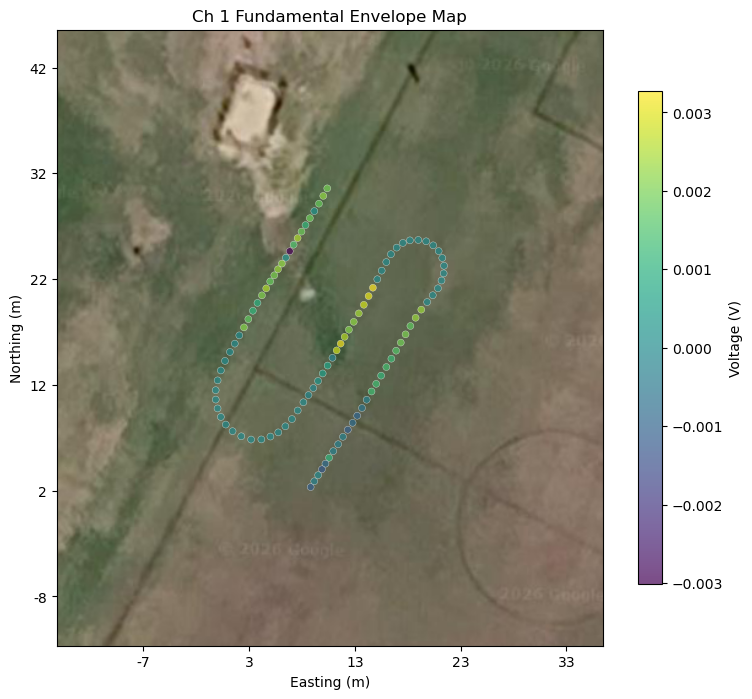

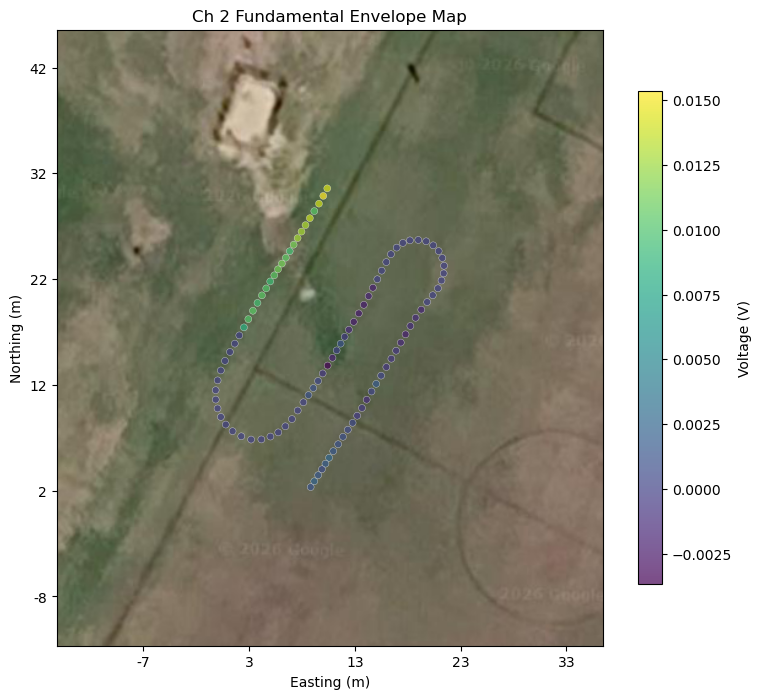

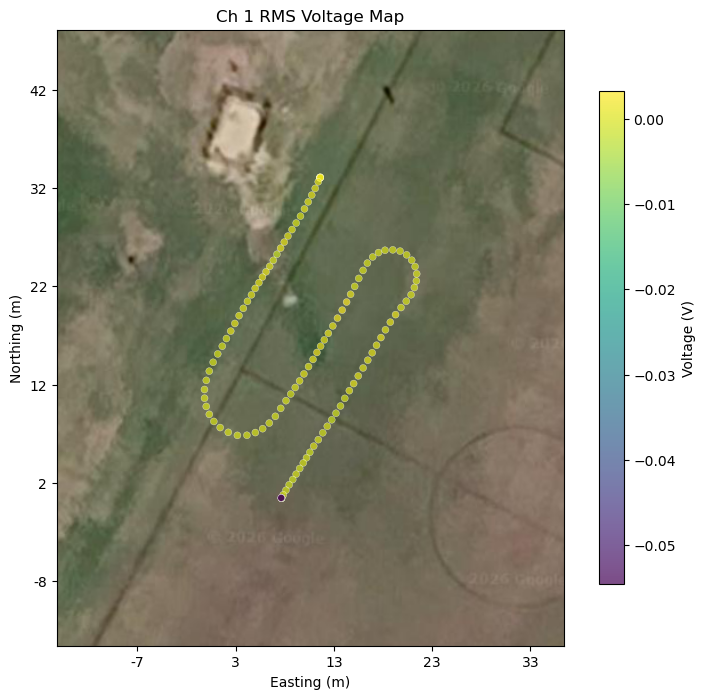

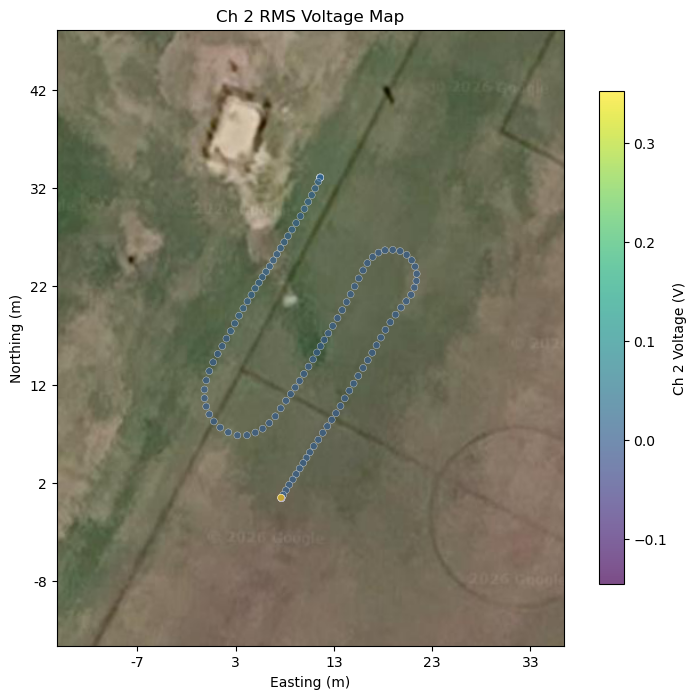

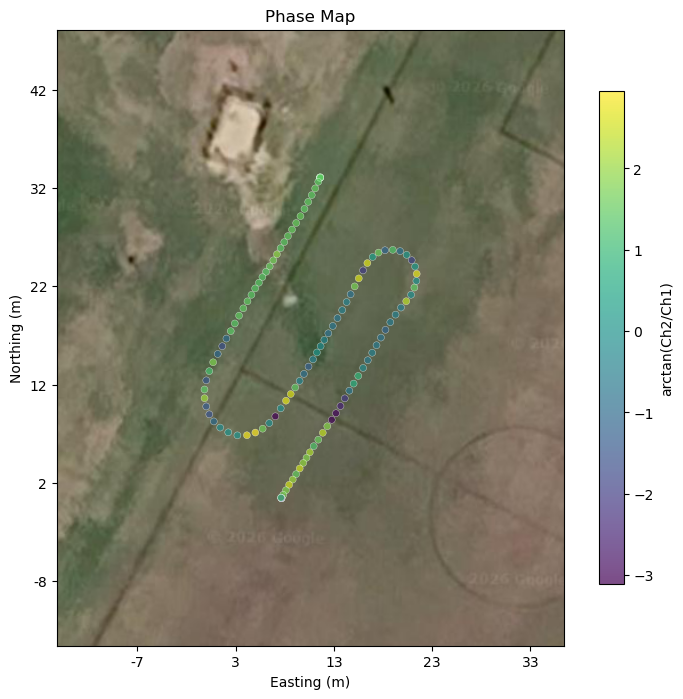

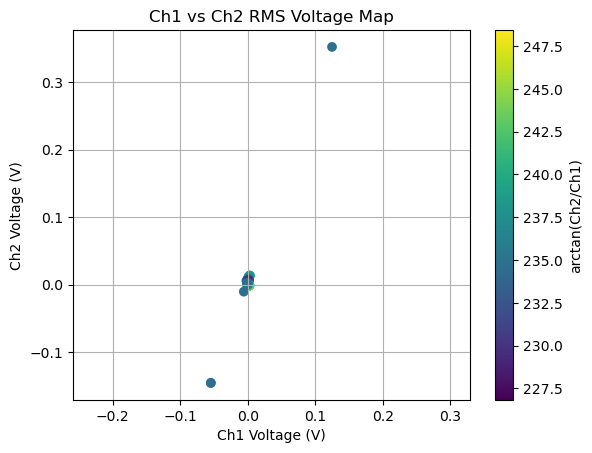

In [116]:
import contextily as ctx
from matplotlib.ticker import FuncFormatter

# Satellite basemap source: Google satellite tiles, or Esri World Imagery as a fallback
basemap_source = 'https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}'
# basemap_source = ctx.providers.Esri.WorldImagery
basemap_zoom = 20  # tile zoom level; 20 is the sharpest Google offers, lower it for large surveys
point_alpha = 0.7  # opacity of the data points over the satellite image
map_padding = 15   # extra map shown around the survey, in [m]

# utm_lat/utm_lon hold UTM easting/northing in [m]; tell the basemap which UTM zone they are in
utm_epsg = f"EPSG:{(32600 if gps_lat[0] >= 0 else 32700) + zone_num}"
utm_origin_x, utm_origin_y = np.min(utm_lat), np.min(utm_lon)

def plot_satellite_map(x, y, values, title, colorbar_label):
    fig, ax = plt.subplots(figsize=(9, 8))
    mag_map = ax.scatter(x, y, c=values, cmap='viridis', s=25, alpha=point_alpha,
                         edgecolors='white', linewidths=0.3, zorder=2)
    ax.set_aspect('equal')
    ax.set_xlim(np.min(x) - map_padding, np.max(x) + map_padding)
    ax.set_ylim(np.min(y) - map_padding, np.max(y) + map_padding)
    ctx.add_basemap(ax, crs=utm_epsg, source=basemap_source, zoom=basemap_zoom, attribution_size=6, zorder=1)
    # Label axes as metres from the survey's south-west corner instead of full UTM values
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v - utm_origin_x:.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v - utm_origin_y:.0f}"))
    fig.colorbar(mag_map, ax=ax, label=colorbar_label, shrink=0.8)
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.set_title(title)
    plt.show()

plot_satellite_map(utm_lat[10:-10], utm_lon[10:-10], mag_ch1_fundamental_envelope_at_gps_coords[10:-10],
                   'Ch 1 Fundamental Envelope Map', 'Voltage (V)')
plot_satellite_map(utm_lat[10:-10], utm_lon[10:-10], mag_ch2_fundamental_envelope_at_gps_coords[10:-10],
                   'Ch 2 Fundamental Envelope Map', 'Voltage (V)')

# ONLY GETTING RID OF LAST DATA POINT IN THIS SPECIFIC CASE BECAUSE IT IS AN OUTLIER IN THE MAPS 
# AND CAUSES THE COLOR SCALE TO BE LESS INFORMATIVE FOR THE REST OF THE DATA
plot_satellite_map(utm_lat[:-1], utm_lon[:-1], mag_ch1_voltages_at_gps_coords[:-1],
                   'Ch 1 RMS Voltage Map', 'Voltage (V)')
plot_satellite_map(utm_lat, utm_lon, mag_ch2_voltages_at_gps_coords,
                   'Ch 2 RMS Voltage Map', 'Ch 2 Voltage (V)')

mag_field_phase = np.arctan2(mag_ch2_voltages_at_gps_coords, mag_ch1_voltages_at_gps_coords)
plot_satellite_map(utm_lat, utm_lon, mag_field_phase, 'Phase Map', 'arctan(Ch2/Ch1)')

mag_map = plt.scatter(x=mag_ch1_voltages_at_gps_coords, y=mag_ch2_voltages_at_gps_coords, c=utm_lat%1000, cmap='viridis')
plt.colorbar(mag_map, label='arctan(Ch2/Ch1)')
plt.xlabel('Ch1 Voltage (V)')
plt.ylabel('Ch2 Voltage (V)')
plt.title('Ch1 vs Ch2 RMS Voltage Map')
plt.axis('equal')
plt.grid(True)
plt.show()

In [51]:
logname = "arcgis_data.csv"
path = os.path.expanduser('data/'+logname)
logfile = open(path, "w")
logfile.write("Times (s),GPS Lat,GPS Lon,Ch 1 Voltage (V),Ch 2 Voltage (V),Phase\n")
for i in range(len(gps_times)):
        logfile.write(f"{gps_times[i]},{gps_lat[i]},{gps_lon[i]},\
                        {mag_ch1_voltages_at_gps_coords[i]:.7f},{mag_ch2_voltages_at_gps_coords[i]:.7f},{mag_field_phase[i]:.7f}\n")
logfile.close()